# Від сигналу до спектрограми: інтерактивний огляд
**Piano sample → Waveform → FFT → Mel Spectrogram → Overtones**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import soundfile as sf
import torch
import torchaudio.transforms as T
import ipywidgets as widgets
from IPython.display import display, Audio
from pathlib import Path

AUDIO_PATH = Path('..') / 'piano_sample.mp3'

# Load audio
data, SR = sf.read(AUDIO_PATH, always_2d=True)
waveform = data.mean(axis=1)          # stereo → mono
TARGET_SR = 22050
# Simple resample
ratio = TARGET_SR / SR
n_out = int(len(waveform) * ratio)
waveform = np.interp(np.linspace(0, len(waveform)-1, n_out), np.arange(len(waveform)), waveform)
SR = TARGET_SR
waveform = waveform / np.abs(waveform).max()

print(f'Audio loaded: {len(waveform)/SR:.2f}s @ {SR} Hz')
display(Audio(waveform, rate=SR))

Audio loaded: 3.34s @ 22050 Hz


## 1. Сигнал у часі (Waveform)
Те що реально зберігається у файлі — амплітуда тиску повітря в кожен момент часу.

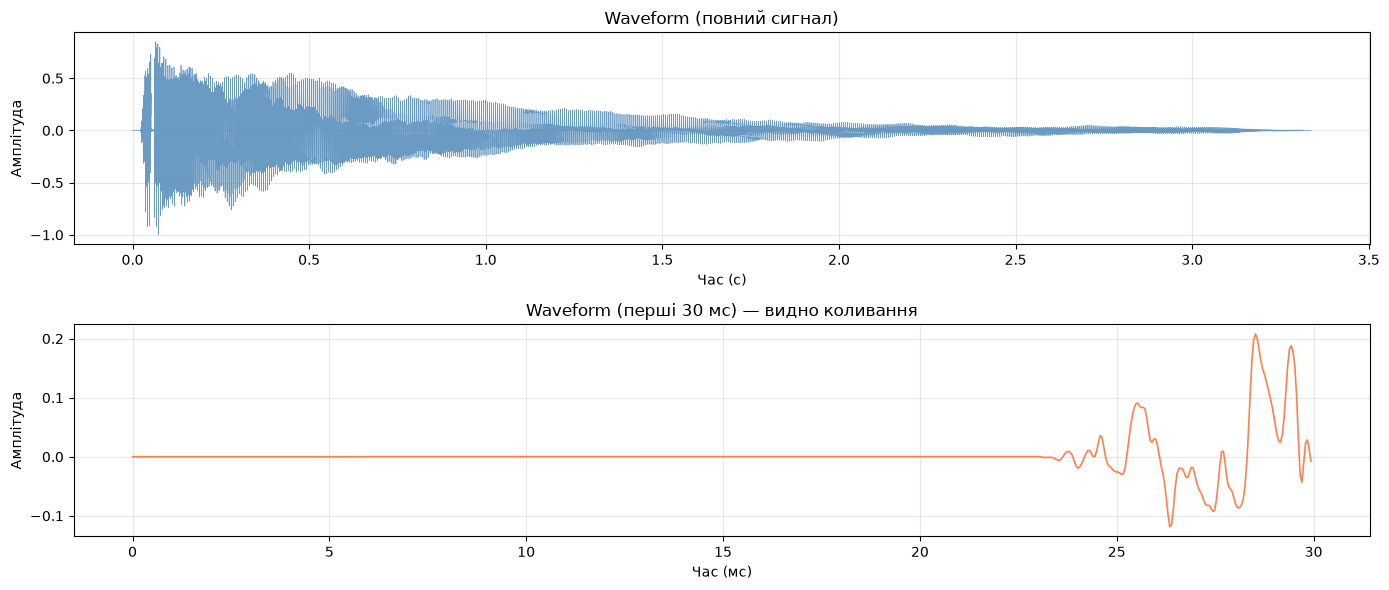

In [2]:
t = np.arange(len(waveform)) / SR

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Full waveform
axes[0].plot(t, waveform, color='steelblue', linewidth=0.5, alpha=0.8)
axes[0].set_xlabel('Час (с)')
axes[0].set_ylabel('Амплітуда')
axes[0].set_title('Waveform (повний сигнал)')
axes[0].grid(alpha=0.3)

# Zoom into first 20ms to see individual oscillations
zoom_ms = 30
zoom_samples = int(zoom_ms / 1000 * SR)
axes[1].plot(t[:zoom_samples]*1000, waveform[:zoom_samples], color='coral', linewidth=1.2)
axes[1].set_xlabel('Час (мс)')
axes[1].set_ylabel('Амплітуда')
axes[1].set_title(f'Waveform (перші {zoom_ms} мс) — видно коливання')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Крок 1 — FFT одного фрейму

Реальний пайплайн починається з нарізання сигналу на короткі фрейми і FFT кожного.
Подивимось що дає FFT на **одному** фреймі (46 мс = 1024 семпли).

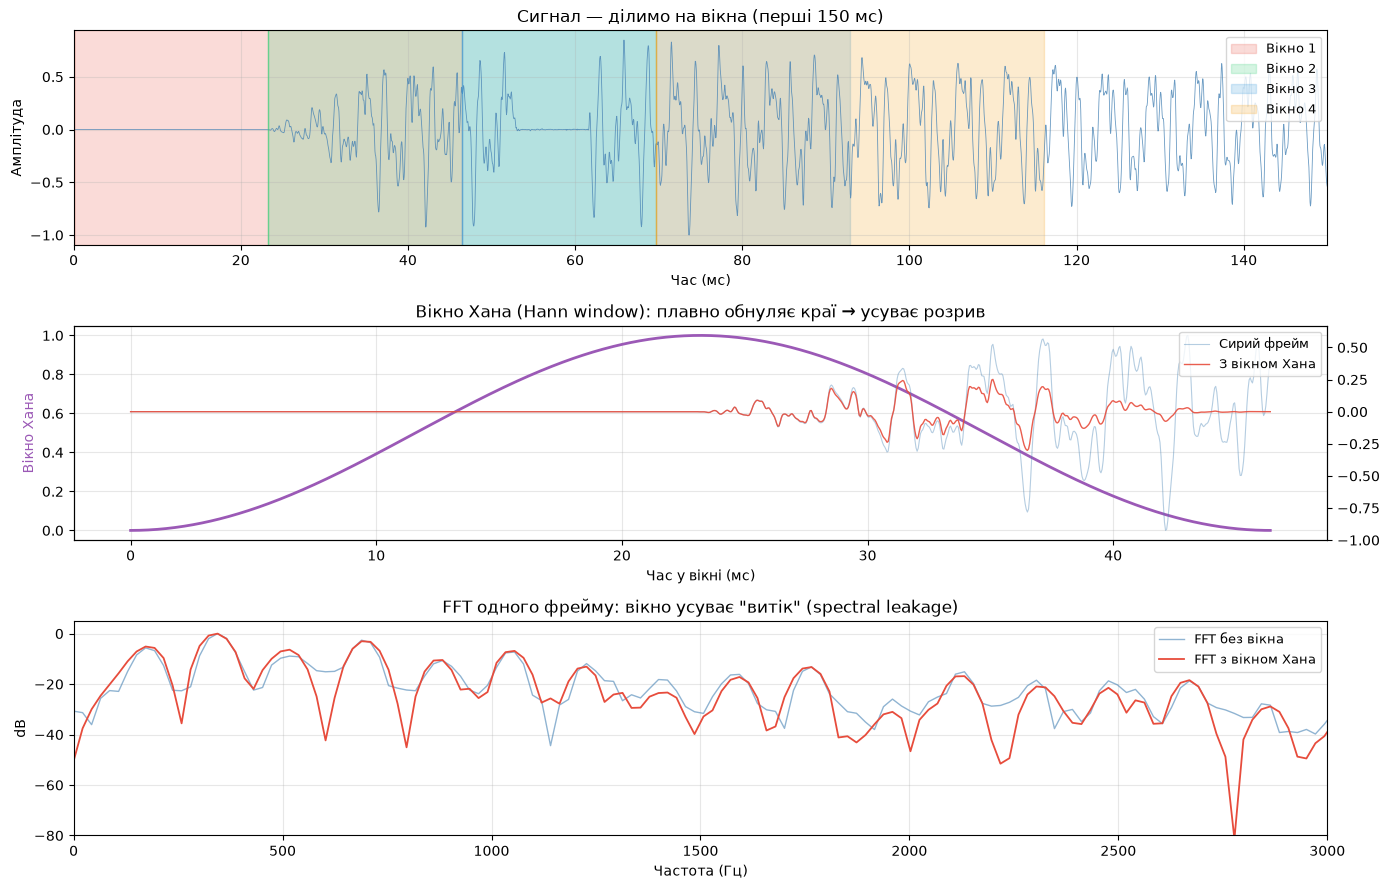

In [3]:
N_FFT = 1024
HOP   = 512
window_fn = np.hanning(N_FFT)

# ── Step 1: Show windowing ────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

t_full = np.arange(len(waveform)) / SR * 1000   # ms

# Full signal
axes[0].plot(t_full, waveform, color='steelblue', linewidth=0.6, alpha=0.8)
axes[0].set_xlim(0, 150)
axes[0].set_xlabel('Час (мс)')
axes[0].set_ylabel('Амплітуда')
axes[0].set_title('Сигнал — ділимо на вікна (перші 150 мс)')
axes[0].grid(alpha=0.3)

# Show 4 windows with colored patches
colors_w = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
for k, color in enumerate(colors_w):
    start = k * HOP
    end   = start + N_FFT
    if end > len(waveform): break
    t_s, t_e = start / SR * 1000, end / SR * 1000
    axes[0].axvspan(t_s, t_e, alpha=0.2, color=color, label=f'Вікно {k+1}')
    axes[0].axvline(t_s, color=color, linewidth=1, alpha=0.6)
axes[0].legend(fontsize=9, loc='upper right')

# ── Step 2: Show Hann window function ─────────────────────────────────────────
axes[1].plot(np.arange(N_FFT) / SR * 1000, window_fn, color='#9b59b6', linewidth=2)
# Overlay raw frame vs windowed frame
frame_raw      = waveform[:N_FFT]
frame_windowed = waveform[:N_FFT] * window_fn
ax1b = axes[1].twinx()
ax1b.plot(np.arange(N_FFT) / SR * 1000, frame_raw,      color='steelblue', alpha=0.4, linewidth=0.8, label='Сирий фрейм')
ax1b.plot(np.arange(N_FFT) / SR * 1000, frame_windowed, color='#e74c3c',   alpha=0.9, linewidth=1,   label='З вікном Хана')
ax1b.legend(fontsize=9, loc='upper right')
axes[1].set_xlabel('Час у вікні (мс)')
axes[1].set_ylabel('Вікно Хана', color='#9b59b6')
axes[1].set_title('Вікно Хана (Hann window): плавно обнуляє краї → усуває розрив')
axes[1].grid(alpha=0.3)

# ── Step 3: FFT of raw vs windowed frame ──────────────────────────────────────
fft_raw  = np.abs(np.fft.rfft(frame_raw))
fft_win  = np.abs(np.fft.rfft(frame_windowed))
f_frame  = np.fft.rfftfreq(N_FFT, 1/SR)

axes[2].plot(f_frame, 20*np.log10(fft_raw/fft_raw.max()+1e-9),
             color='steelblue', alpha=0.6, linewidth=1, label='FFT без вікна')
axes[2].plot(f_frame, 20*np.log10(fft_win/fft_win.max()+1e-9),
             color='#e74c3c', linewidth=1.3, label='FFT з вікном Хана')
axes[2].set_xlim(0, 3000)
axes[2].set_ylim(-80, 5)
axes[2].set_xlabel('Частота (Гц)')
axes[2].set_ylabel('dB')
axes[2].set_title('FFT одного фрейму: вікно усуває "витік" (spectral leakage)')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

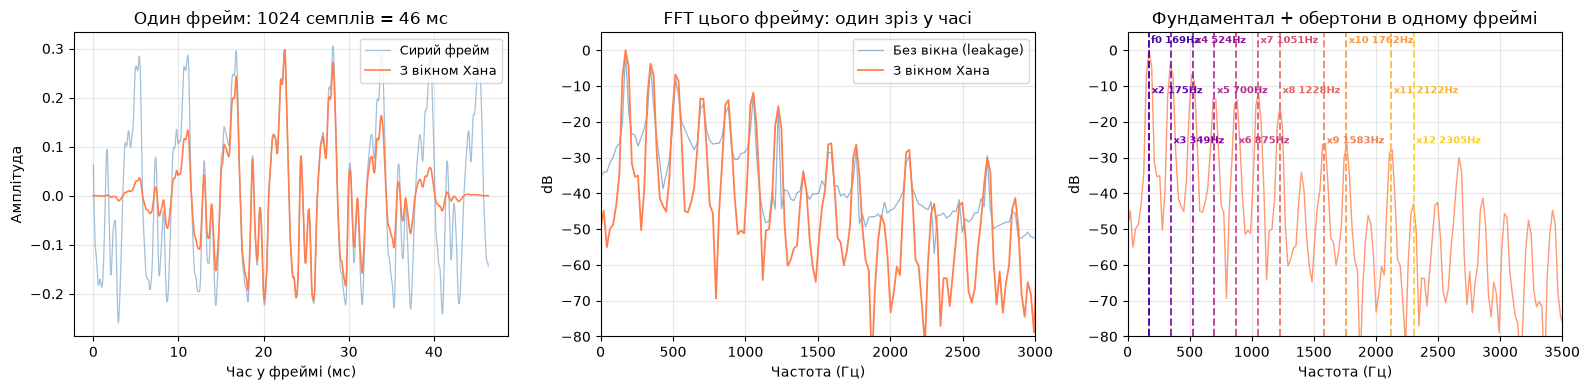

Fundamental: 168.8 Hz
Обертони:    ['175', '349', '524', '700', '875', '1051', '1228', '1583', '1762', '2122', '2305']

Цей FFT — лише один момент часу.
Щоб бачити як частоти змінюються з часом -> STFT.


In [4]:
N_FFT     = 1024
HOP       = 512
window_fn = np.hanning(N_FFT)

# Pick one frame from the middle of the signal (more stable than onset)
frame_start    = len(waveform) // 4
frame_raw      = waveform[frame_start: frame_start + N_FFT]
frame_windowed = frame_raw * window_fn

fft_raw = np.fft.rfft(frame_raw)
fft_win = np.fft.rfft(frame_windowed)
fft_freqs = np.fft.rfftfreq(N_FFT, 1/SR)   # 513 bins — for one frame

fft_raw_db = 20 * np.log10(np.abs(fft_raw) / np.abs(fft_raw).max() + 1e-9)
fft_win_db = 20 * np.log10(np.abs(fft_win) / np.abs(fft_win).max() + 1e-9)

# Global FFT (full signal) — separate freq axis, used only for peak detection + synth
fft_vals       = np.abs(np.fft.rfft(waveform))
fft_freqs_glob = np.fft.rfftfreq(len(waveform), 1/SR)   # len(waveform)//2+1 bins
fft_glob_db    = 20 * np.log10(fft_vals / fft_vals.max() + 1e-9)

from scipy.signal import find_peaks
mask_g   = fft_freqs_glob < 4000
peaks_g, _ = find_peaks(fft_glob_db[mask_g], height=-30, distance=20)
peak_freqs_g = fft_freqs_glob[mask_g][peaks_g]
peak_amps_g  = fft_glob_db[mask_g][peaks_g]
top_idx   = np.argsort(peak_amps_g)[-12:]
top_freqs = np.sort(peak_freqs_g[top_idx])

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. The frame in time domain
t_frame = np.arange(N_FFT) / SR * 1000
axes[0].plot(t_frame, frame_raw,       color='steelblue', alpha=0.5, linewidth=0.9, label='Сирий фрейм')
axes[0].plot(t_frame, frame_windowed,  color='coral',     linewidth=1.2,            label='З вікном Хана')
axes[0].set_xlabel('Час у фреймі (мс)')
axes[0].set_ylabel('Амплітуда')
axes[0].set_title(f'Один фрейм: {N_FFT} семплів = {N_FFT/SR*1000:.0f} мс')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# 2. FFT with vs without window
axes[1].plot(fft_freqs, fft_raw_db, color='steelblue', alpha=0.6,
             linewidth=0.9, label='Без вікна (leakage)')
axes[1].plot(fft_freqs, fft_win_db, color='coral',
             linewidth=1.3, label='З вікном Хана')
axes[1].set_xlim(0, 3000)
axes[1].set_ylim(-80, 5)
axes[1].set_xlabel('Частота (Гц)')
axes[1].set_ylabel('dB')
axes[1].set_title('FFT цього фрейму: один зріз у часі')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

# 3. Annotate overtones
axes[2].plot(fft_freqs, fft_win_db, color='coral', linewidth=1.0, alpha=0.8)
axes[2].set_xlim(0, 3500)
axes[2].set_ylim(-80, 5)
axes[2].set_xlabel('Частота (Гц)')
axes[2].set_ylabel('dB')
axes[2].set_title('Фундаментал + обертони в одному фреймі')
axes[2].grid(alpha=0.3)

colors_ov = plt.cm.plasma(np.linspace(0.1, 0.9, len(top_freqs)))
for j, (f, c) in enumerate(zip(top_freqs, colors_ov)):
    if f > 3500: continue
    axes[2].axvline(f, color=c, linewidth=1.4, linestyle='--', alpha=0.85)
    label = f'f0 {f:.0f}Hz' if j == 0 else f'x{j+1} {f:.0f}Hz'
    axes[2].text(f + 20, 2 - (j % 3) * 14, label, fontsize=7.5, color=c, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Fundamental: {top_freqs[0]:.1f} Hz')
print(f'Обертони:    {[f"{f:.0f}" for f in top_freqs[1:]]}')
print()
print('Цей FFT — лише один момент часу.')
print('Щоб бачити як частоти змінюються з часом -> STFT.')


## 3. Від FFT до STFT (Short-Time Fourier Transform)

**Проблема FFT:** один спектр для всього сигналу — не видно як частоти змінюються в часі.

**Рішення STFT:** ділимо сигнал на короткі вікна, робимо FFT кожного → отримуємо спектр у часі.

```
Сигнал:  [========================================]
                   ↓ нарізаємо вікна (N_FFT=1024)
Вікно 1: [====    ]  → FFT → [спектр 1]
Вікно 2:   [====  ]  → FFT → [спектр 2]   ← перекриття (hop=512)
Вікно 3:     [====]  → FFT → [спектр 3]
...
                   ↓ стекаємо
Спектрограма: матриця [частота × час]
```

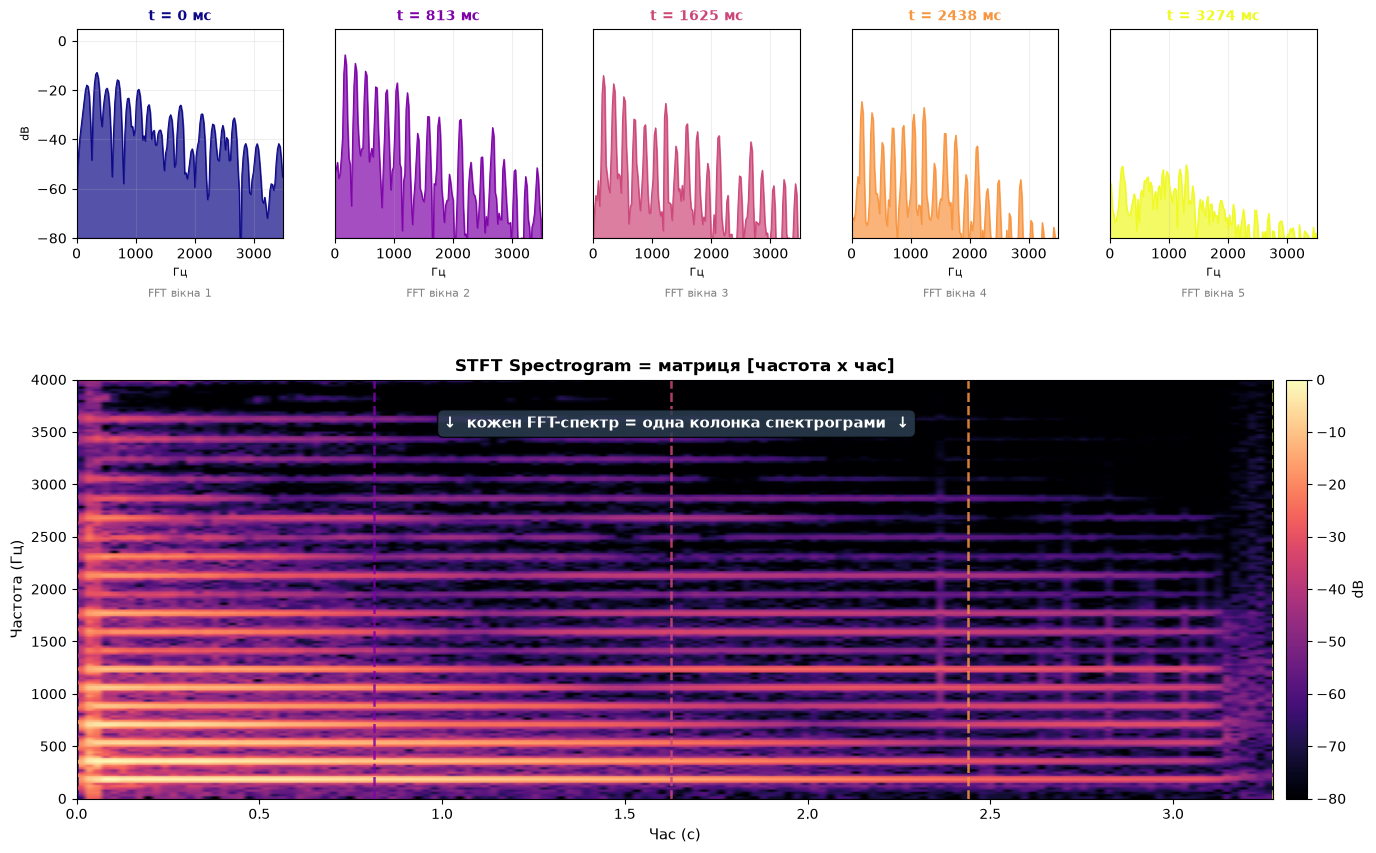

Розмір STFT матриці: 513 частот x 142 фреймів
Роздільність по частоті: 21.5 Гц/бін
Роздільність по часу:    23.2 мс/фрейм


In [5]:
# ── Build STFT manually, frame by frame ──────────────────────────────────────
n_frames    = (len(waveform) - N_FFT) // HOP + 1
n_freqs     = N_FFT // 2 + 1
spectrogram = np.zeros((n_freqs, n_frames))

for k in range(n_frames):
    start = k * HOP
    frame = waveform[start: start + N_FFT] * window_fn
    if len(frame) < N_FFT:
        frame = np.pad(frame, (0, N_FFT - len(frame)))
    spectrogram[:, k] = np.abs(np.fft.rfft(frame))

spec_db_manual = 20 * np.log10(spectrogram / spectrogram.max() + 1e-9)
freqs_stft     = np.fft.rfftfreq(N_FFT, 1/SR)
times_stft     = np.arange(n_frames) * HOP / SR

# ── Visualize: 5 frames (top) → full spectrogram (bottom) ────────────────────
N_SHOW     = 5
frame_idxs = np.linspace(0, n_frames - 1, N_SHOW, dtype=int)
cmap_show  = plt.cm.plasma

fig = plt.figure(figsize=(16, 10))
gs  = fig.add_gridspec(2, N_SHOW, height_ratios=[1, 2], hspace=0.45, wspace=0.25)

# Top row: individual FFT frames
for j, k in enumerate(frame_idxs):
    ax = fig.add_subplot(gs[0, j])
    color = cmap_show(j / (N_SHOW - 1))
    ax.fill_between(freqs_stft, spec_db_manual[:, k], -80,
                    alpha=0.7, color=color)
    ax.plot(freqs_stft, spec_db_manual[:, k], color=color, linewidth=0.8)
    ax.set_xlim(0, 3500)
    ax.set_ylim(-80, 5)
    ax.set_title(f't = {times_stft[k]*1000:.0f} мс', fontsize=10, fontweight='bold', color=color)
    ax.set_xlabel('Гц', fontsize=8)
    if j == 0:
        ax.set_ylabel('dB', fontsize=8)
    else:
        ax.set_yticks([])
    ax.grid(alpha=0.2)
    ax.text(0.5, -0.28, f'FFT вікна {j+1}', transform=ax.transAxes,
            ha='center', fontsize=8, color='gray')

# Arrow in the middle between rows
fig.text(0.5, 0.485, '↓  кожен FFT-спектр = одна колонка спектрограми  ↓',
         ha='center', va='center', fontsize=11, color='white', fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#2c3e50', alpha=0.85))

# Bottom row: full spectrogram spanning all columns
ax_spec = fig.add_subplot(gs[1, :])
im = ax_spec.imshow(spec_db_manual, aspect='auto', origin='lower', cmap='magma',
                    vmin=-80, vmax=0,
                    extent=[times_stft[0], times_stft[-1],
                            freqs_stft[0], freqs_stft[-1]])
ax_spec.set_ylim(0, 4000)
ax_spec.set_xlabel('Час (с)', fontsize=11)
ax_spec.set_ylabel('Частота (Гц)', fontsize=11)
ax_spec.set_title('STFT Spectrogram = матриця [частота x час]',
                  fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax_spec, label='dB', fraction=0.025, pad=0.01)

# Draw vertical lines on spectrogram at the shown frame times + arrows from top
for j, k in enumerate(frame_idxs):
    color = cmap_show(j / (N_SHOW - 1))
    ax_spec.axvline(times_stft[k], color=color, linewidth=1.8,
                    linestyle='--', alpha=0.85)

plt.show()
print(f'Розмір STFT матриці: {spec_db_manual.shape[0]} частот x {spec_db_manual.shape[1]} фреймів')
print(f'Роздільність по частоті: {SR/N_FFT:.1f} Гц/бін')
print(f'Роздільність по часу:    {HOP/SR*1000:.1f} мс/фрейм')


## 4. Від STFT до Mel Spectrogram

**Проблема лінійного спектру:** людське вухо сприймає частоти **логарифмічно**.
Різниця між 100 і 200 Гц звучить так само "далеко" як між 1000 і 2000 Гц.

**Мел-шкала** моделює це сприйняття:
```
mel = 2595 × log10(1 + Hz/700)
```

**Mel filterbank:** набір трикутних фільтрів рівномірно розміщених на мел-шкалі.
Кожен фільтр підсумовує енергію STFT у своєму діапазоні → один мел-бін.

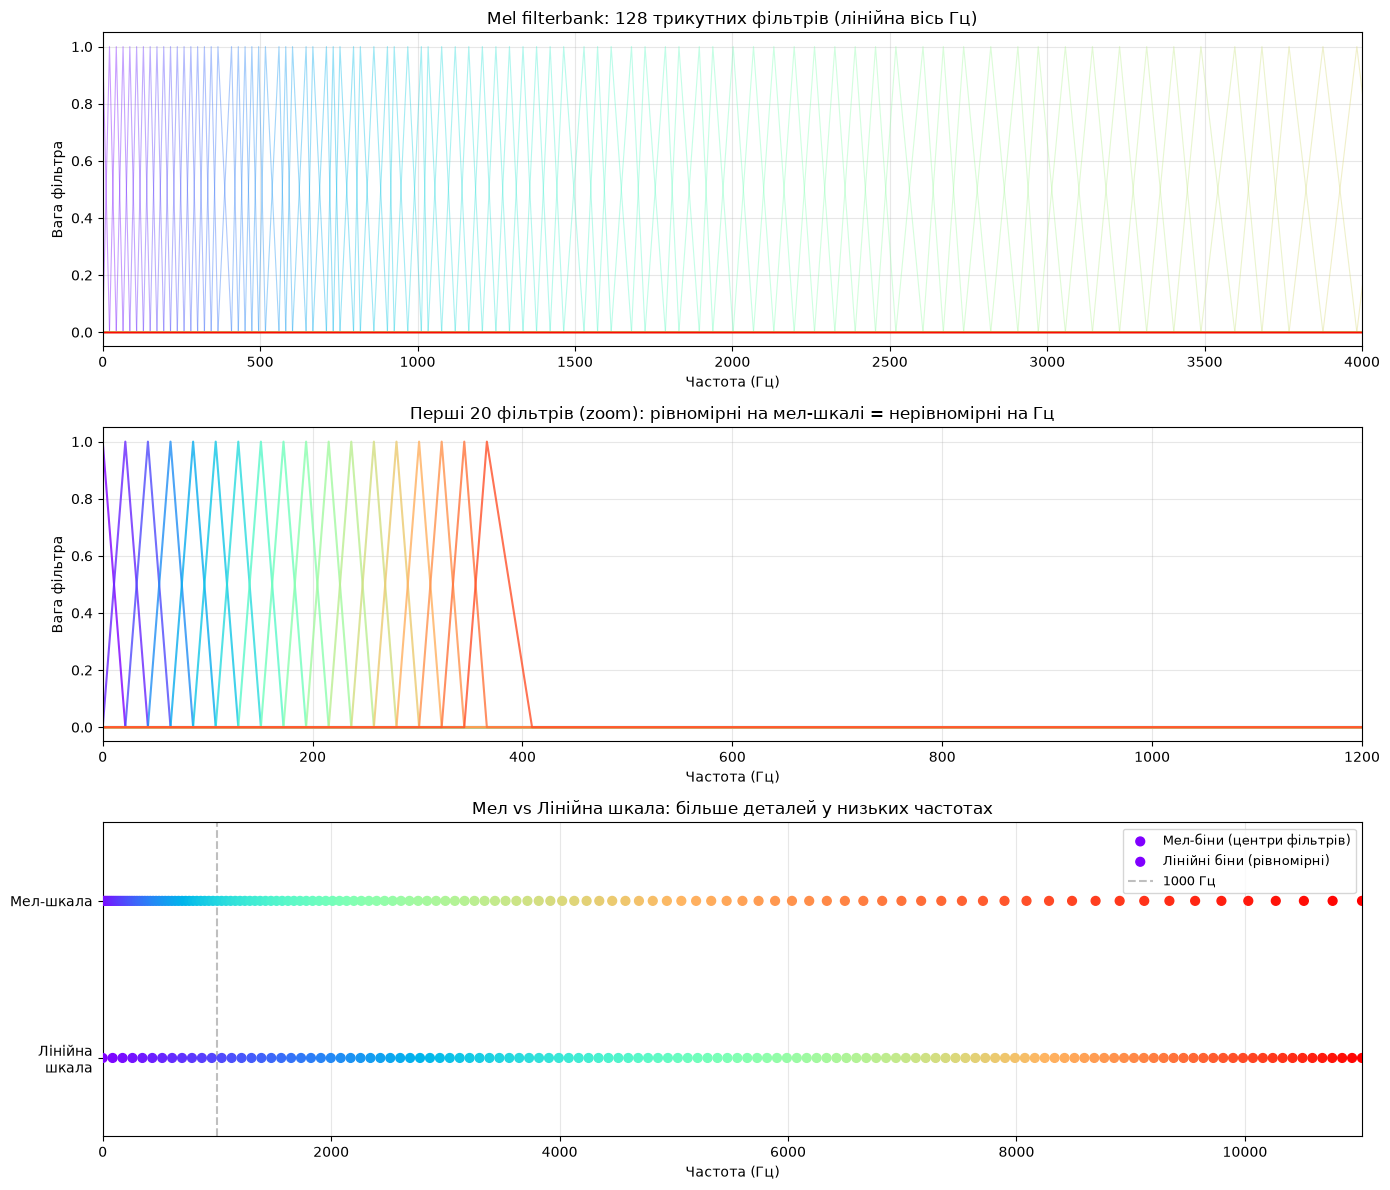

In [6]:
N_MELS = 128
f_min, f_max = 0, SR // 2

# ── Build mel filterbank manually ─────────────────────────────────────────────
def hz_to_mel(hz):   return 2595 * np.log10(1 + hz / 700)
def mel_to_hz(mel):  return 700 * (10**(mel / 2595) - 1)

mel_min = hz_to_mel(f_min + 1)
mel_max = hz_to_mel(f_max)
mel_points = np.linspace(mel_min, mel_max, N_MELS + 2)
hz_points  = mel_to_hz(mel_points)

# Map hz_points to STFT bin indices
fft_bins_all = np.floor((N_FFT + 1) * hz_points / SR).astype(int)
fft_bins_all = np.clip(fft_bins_all, 0, n_freqs - 1)

filterbank = np.zeros((N_MELS, n_freqs))
for m in range(1, N_MELS + 1):
    f_left, f_center, f_right = fft_bins_all[m-1], fft_bins_all[m], fft_bins_all[m+1]
    for k in range(f_left, f_center):
        if f_center != f_left:
            filterbank[m-1, k] = (k - f_left) / (f_center - f_left)
    for k in range(f_center, f_right):
        if f_right != f_center:
            filterbank[m-1, k] = (f_right - k) / (f_right - f_center)

# ── Plot filterbank ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# All filters
colors_fb = plt.cm.rainbow(np.linspace(0, 1, N_MELS))
for m in range(N_MELS):
    axes[0].plot(freqs_stft, filterbank[m], color=colors_fb[m], alpha=0.4, linewidth=0.8)
axes[0].set_xlim(0, 4000)
axes[0].set_xlabel('Частота (Гц)')
axes[0].set_ylabel('Вага фільтра')
axes[0].set_title(f'Mel filterbank: {N_MELS} трикутних фільтрів (лінійна вісь Гц)')
axes[0].grid(alpha=0.3)

# First 20 filters zoomed — show triangular shape clearly
for m in range(20):
    axes[1].plot(freqs_stft, filterbank[m], color=colors_fb[m*6], linewidth=1.5, alpha=0.8)
axes[1].set_xlim(0, 1200)
axes[1].set_xlabel('Частота (Гц)')
axes[1].set_ylabel('Вага фільтра')
axes[1].set_title('Перші 20 фільтрів (zoom): рівномірні на мел-шкалі = нерівномірні на Гц')
axes[1].grid(alpha=0.3)

# Show mel scale vs linear
ax_mel = axes[2]
mel_freqs_center = mel_to_hz(np.linspace(mel_min, mel_max, N_MELS))
ax_mel.scatter(mel_freqs_center, np.ones(N_MELS) * 1.5,
               c=colors_fb, s=40, zorder=3, label='Мел-біни (центри фільтрів)')
ax_mel.scatter(np.linspace(0, f_max, N_MELS), np.ones(N_MELS) * 0.5,
               c=colors_fb, s=40, zorder=3, label='Лінійні біни (рівномірні)')
ax_mel.set_xlim(0, f_max)
ax_mel.set_ylim(0, 2)
ax_mel.set_yticks([0.5, 1.5])
ax_mel.set_yticklabels(['Лінійна\nшкала', 'Мел-шкала'], fontsize=10)
ax_mel.set_xlabel('Частота (Гц)')
ax_mel.set_title('Мел vs Лінійна шкала: більше деталей у низьких частотах')
ax_mel.axvline(1000, color='gray', linestyle='--', alpha=0.5, label='1000 Гц')
ax_mel.legend(fontsize=9, loc='upper right')
ax_mel.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

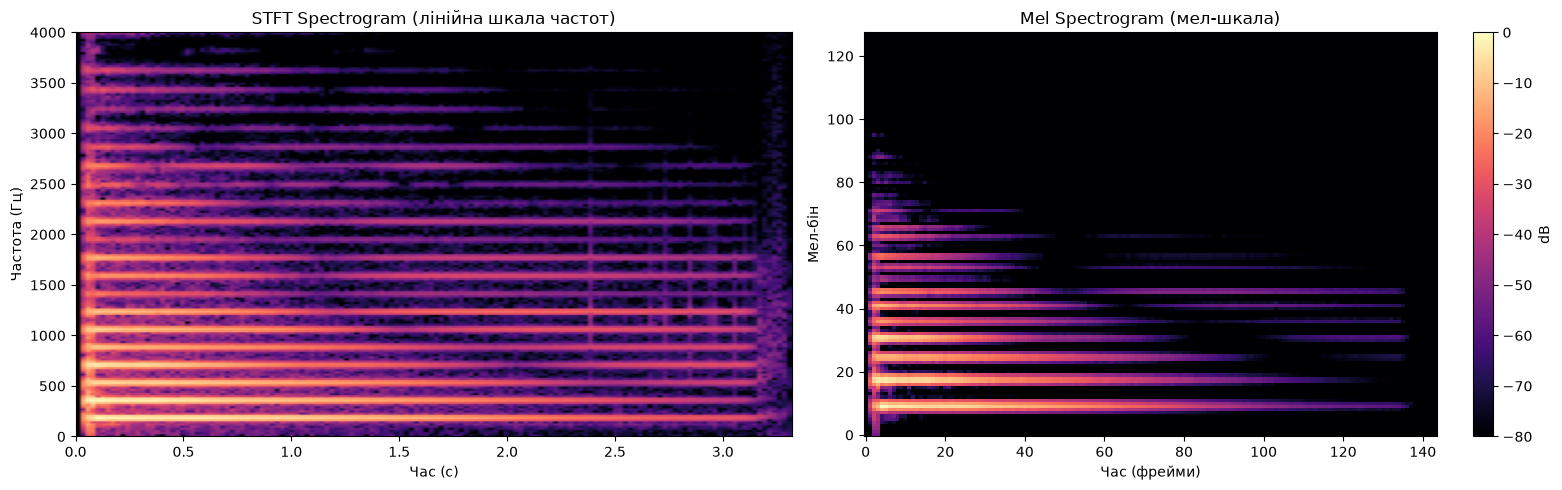

In [7]:
N_FFT    = 1024
HOP      = 512
N_MELS   = 128

wav_t = torch.from_numpy(waveform).float().unsqueeze(0)  # [1, T]

# STFT spectrogram (linear frequency)
stft = torch.stft(wav_t.squeeze(0), n_fft=N_FFT, hop_length=HOP,
                  window=torch.hann_window(N_FFT), return_complex=True)
spec_linear = stft.abs().numpy()          # [freq_bins, time_frames]
spec_db     = 20 * np.log10(spec_linear / spec_linear.max() + 1e-9)

# Mel spectrogram
mel_transform = T.MelSpectrogram(sample_rate=SR, n_fft=N_FFT,
                                  hop_length=HOP, n_mels=N_MELS)
mel = mel_transform(wav_t).squeeze(0).numpy()
mel_db = 20 * np.log10(mel / mel.max() + 1e-9)

freq_bins = np.fft.rfftfreq(N_FFT, 1/SR)
time_frames = np.arange(spec_db.shape[1]) * HOP / SR

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].imshow(spec_db, aspect='auto', origin='lower', cmap='magma',
               vmin=-80, vmax=0,
               extent=[0, time_frames[-1], freq_bins[0], freq_bins[-1]])
axes[0].set_ylim(0, 4000)
axes[0].set_xlabel('Час (с)')
axes[0].set_ylabel('Частота (Гц)')
axes[0].set_title('STFT Spectrogram (лінійна шкала частот)')

im = axes[1].imshow(mel_db, aspect='auto', origin='lower', cmap='magma',
                    vmin=-80, vmax=0)
axes[1].set_xlabel('Час (фрейми)')
axes[1].set_ylabel('Мел-бін')
axes[1].set_title('Mel Spectrogram (мел-шкала)')
plt.colorbar(im, ax=axes[1], label='dB')

plt.tight_layout()
plt.show()

## 4. Інтерактивно: додавай і прибирай обертони — чуй різницю
Фільтруємо реальний запис піаніно через FFT: прибираємо обрані обертони і відтворюємо результат.

In [8]:
# Auto-detect fundamental from FFT peaks
fundamental = float(top_freqs[0])
N_OVERTONES_MAX = 20

overtone_freqs_all = [fundamental * (i+1) for i in range(N_OVERTONES_MAX)
                      if fundamental * (i+1) < SR / 2]

fft_full       = np.fft.rfft(waveform)
fft_freqs_local = np.fft.rfftfreq(len(waveform), 1/SR)
fft_orig_db    = 20 * np.log10(np.abs(fft_full) / np.abs(fft_full).max() + 1e-9)

# ── Widgets ───────────────────────────────────────────────────────────────────
fund_box = widgets.FloatText(
    value=round(fundamental, 1),
    description='Fundamental (Гц):',
    style={'description_width': '150px'},
    layout=widgets.Layout(width='280px')
)
bw_box = widgets.IntSlider(
    value=50, min=10, max=200, step=5,
    description='Ширина смуги (Гц):',
    style={'description_width': '170px'},
    layout=widgets.Layout(width='420px')
)

overtone_checks = []
for i, f in enumerate(overtone_freqs_all):
    cb = widgets.Checkbox(
        value=True,
        description=f'x{i+1}  {f:.0f} Hz',
        indent=False,
        layout=widgets.Layout(width='140px')
    )
    overtone_checks.append(cb)

checks_grid = widgets.GridBox(
    overtone_checks,
    layout=widgets.Layout(grid_template_columns='repeat(4, 150px)', grid_gap='4px 4px')
)

btn_all       = widgets.Button(description='Всі ON',    button_style='success', layout=widgets.Layout(width='110px'))
btn_none      = widgets.Button(description='Всі OFF',   button_style='danger',  layout=widgets.Layout(width='110px'))
btn_only_fund = widgets.Button(description='Тільки f0', button_style='warning', layout=widgets.Layout(width='120px'))

def set_all(b):
    for cb in overtone_checks: cb.value = True
def set_none(b):
    for cb in overtone_checks: cb.value = False
def set_only_fund(b):
    for i, cb in enumerate(overtone_checks): cb.value = (i == 0)

btn_all.on_click(set_all)
btn_none.on_click(set_none)
btn_only_fund.on_click(set_only_fund)

filter_out = widgets.Output()

def rebuild(*args):
    with filter_out:
        filter_out.clear_output(wait=True)

        fund = fund_box.value
        bw   = bw_box.value

        active_freqs  = [fund * (i+1) for i, cb in enumerate(overtone_checks)
                         if cb.value and fund * (i+1) < SR / 2]
        removed_freqs = [fund * (i+1) for i, cb in enumerate(overtone_checks)
                         if not cb.value and fund * (i+1) < SR / 2]

        # ADDITIVE approach: start with zeros, copy only active bands
        fft_filtered = np.zeros_like(fft_full)
        for f in active_freqs:
            mask = (fft_freqs_local >= f - bw) & (fft_freqs_local <= f + bw)
            fft_filtered[mask] = fft_full[mask]

        signal_filtered = np.fft.irfft(fft_filtered, n=len(waveform))
        peak = np.abs(signal_filtered).max()
        if peak > 0:
            signal_filtered = signal_filtered / peak * 0.8

        fft_filt_db = 20 * np.log10(np.abs(fft_filtered) / (np.abs(fft_full).max() + 1e-9) + 1e-9)

        # ── Plot ────────────────────────────────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(15, 4))

        max_show = min(max(active_freqs[-1] if active_freqs else fund,
                           removed_freqs[-1] if removed_freqs else fund) * 1.4, SR/2)

        axes[0].plot(fft_freqs_local, fft_orig_db, color='#6baed6',
                     linewidth=0.8, alpha=0.5, label='Оригінал', zorder=1)
        axes[0].plot(fft_freqs_local, fft_filt_db, color='#fd8d3c',
                     linewidth=1.2, label='Активні обертони', zorder=2)

        cmap = plt.cm.plasma
        all_freqs = [fund * (j+1) for j in range(len(overtone_checks)) if fund*(j+1) < SR/2]
        for i, f in enumerate(all_freqs):
            color = cmap(i / len(overtone_freqs_all))
            is_active = any(abs(af - f) < 1 for af in active_freqs)
            axes[0].axvspan(f - bw, f + bw, alpha=0.3 if is_active else 0.05, color=color)
            axes[0].axvline(f, color=color,
                            linewidth=1.5 if is_active else 0.4,
                            linestyle='-' if is_active else '--',
                            alpha=1.0 if is_active else 0.25)
            if f < max_show * 0.95:
                label = 'f0' if i == 0 else f'x{i+1}'
                axes[0].text(f, 3 - (i % 3) * 9, label, ha='center',
                             fontsize=7.5, color=color,
                             fontweight='bold' if is_active else 'normal',
                             alpha=1.0 if is_active else 0.4, zorder=4)

        axes[0].set_xlim(0, max_show)
        axes[0].set_ylim(-90, 8)
        axes[0].set_xlabel('Частота (Гц)')
        axes[0].set_ylabel('dB')
        axes[0].set_title(f'FFT: {len(active_freqs)} активних / {len(all_freqs)} обертонів')
        axes[0].legend(fontsize=9)
        axes[0].grid(alpha=0.2)

        zoom = int(0.05 * SR)
        t_z = np.arange(zoom) / SR * 1000
        axes[1].plot(t_z, waveform[:zoom], color='#6baed6',
                     alpha=0.5, linewidth=1, label='Оригінал')
        axes[1].plot(t_z, signal_filtered[:zoom], color='#fd8d3c',
                     linewidth=1.3, label='Відфільтрований')
        axes[1].set_xlabel('Час (мс)')
        axes[1].set_ylabel('Амплітуда')
        axes[1].set_title('Waveform: перші 50 мс')
        axes[1].legend(fontsize=9)
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

        if active_freqs:
            print(f'Активні: {[f"{f:.0f} Hz" for f in active_freqs]}')
        else:
            print('Всі обертони вимкнені — тиша')
        display(Audio(signal_filtered, rate=SR, autoplay=False))

for cb in overtone_checks:
    cb.observe(rebuild, names='value')
fund_box.observe(rebuild, names='value')
bw_box.observe(rebuild, names='value')

display(widgets.VBox([
    widgets.HBox([fund_box, bw_box]),
    widgets.HBox([btn_all, btn_none, btn_only_fund]),
    checks_grid,
    filter_out
]))
rebuild()


## 5. Синтез: як обертони формують тембр
Відтворимо звук тільки з виділених обертонів — почуємо як тембр залежить від набору частот.

§## 6. HarmonicCNN: що бачить кожен канал
Той самий мел-спектрограм, зсунутий на 0/1/2/3 октави.

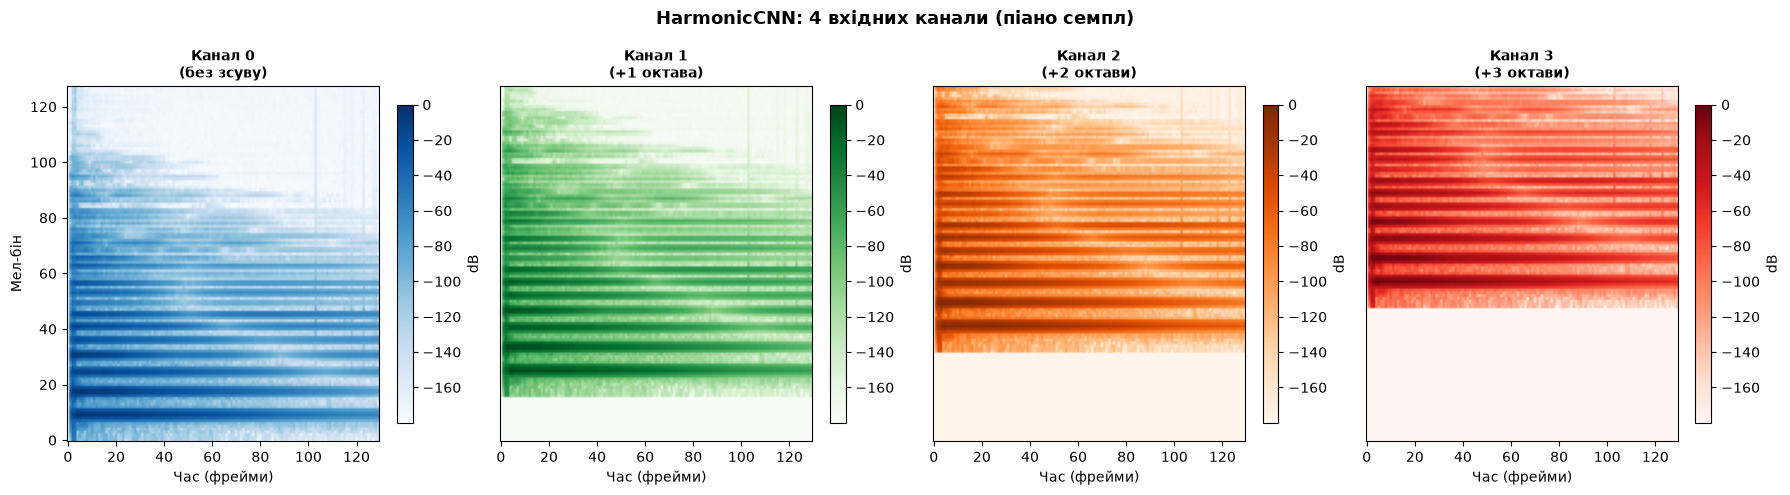

In [9]:
TIME_FRAMES = 130
OCTAVE_BINS = N_MELS // 8   # ~16 bins per octave

# Crop mel to TIME_FRAMES
mel_crop = mel_db[:, :TIME_FRAMES] if mel_db.shape[1] >= TIME_FRAMES else \
           np.pad(mel_db, ((0,0),(0, TIME_FRAMES - mel_db.shape[1])))

def octave_shift(m, n):
    shift = n * OCTAVE_BINS
    out = np.full_like(m, m.min())
    if shift < N_MELS:
        out[shift:, :] = m[:N_MELS-shift, :]
    return out

channels = [octave_shift(mel_crop, i) for i in range(4)]
names    = ['Канал 0\n(без зсуву)', 'Канал 1\n(+1 октава)',
            'Канал 2\n(+2 октави)', 'Канал 3\n(+3 октави)']
cmaps    = ['Blues', 'Greens', 'Oranges', 'Reds']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('HarmonicCNN: 4 вхідних канали (піано семпл)', fontsize=13, fontweight='bold')

vmin, vmax = mel_crop.min(), mel_crop.max()
for i, (ch, name, cm) in enumerate(zip(channels, names, cmaps)):
    im = axes[i].imshow(ch, aspect='auto', origin='lower', cmap=cm, vmin=vmin, vmax=vmax)
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Час (фрейми)')
    if i == 0:
        axes[i].set_ylabel('Мел-бін')
    else:
        axes[i].set_yticks([])
    plt.colorbar(im, ax=axes[i], fraction=0.046, label='dB')

plt.tight_layout()
plt.show()